# Facial Expression Recognition — Eksperimen Bobot Loss Fear 1,25×

**Latihan untuk pemula · Google Colab · CNN dibuat dari awal**

Tujuan: mempelajari alur **gambar → tensor → CNN → prediksi kelas ekspresi**.
Penjelasan menggunakan bahasa Indonesia; kode dan nama hasil menggunakan bahasa Inggris.
Notebook ini belum dilatih. Angka akurasi hanya akan muncul setelah kamu menjalankannya.

Dataset: [Human Face Emotions — Samith Sachidanandan, Kaggle](https://www.kaggle.com/datasets/samithsachidanandan/human-face-emotions).
ZIP yang diperiksa berisi 59.099 file: Angry 10.148, Fear 9.732, Happy 18.439,
Sad 12.553, dan Suprise 8.227. Nama folder **`Suprise`** dipertahankan saat membaca data;
nama yang ditampilkan diperbaiki menjadi **`Surprise`**. Filemu tidak memiliki pembagian train/validation/test.

## Sebelum mulai
1. Upload **`archive (1).zip`** ke **My Drive** di Google Drive. Tidak perlu mengekstraknya di Drive.
2. Di Colab, pilih **Runtime → Change runtime type → GPU** (misalnya T4, bila tersedia).
3. Jalankan sel berurutan dengan tombol ▶ di kiri. Baca penjelasannya sebelum menjalankan sel berikutnya.
4. Pada bagian 2, sesuaikan `ZIP_PATH` dengan lokasi ZIP di Drive.

Data akan diekstrak ke penyimpanan sementara Colab supaya pembacaan gambar lebih cepat.
Hasil disimpan di **MyDrive/fer_cnn_outputs/simplecnn_mild_aug_adamw_fear125_v1/<waktu_run>/** agar bertahan setelah runtime berakhir.
Ketersediaan GPU dan lama sesi Colab bervariasi. [Colab FAQ](https://research.google.com/colaboratory/faq.html)

**Batas latihan:** model memprediksi label ekspresi pada gambar. Evaluasi ini tidak mengukur diagnosis depresi
atau memastikan perasaan seseorang. Tidak ada ID orang yang andal; hasil split gambar bukan evaluasi orang baru.

## 1. Siapkan library
**PyTorch** membangun dan melatih CNN; **torchvision** mengubah gambar menjadi tensor;
**scikit-learn** membantu pembagian data dan evaluasi. Sel berikut hanya memasang paket yang belum ada.

In [1]:
import importlib.util
import subprocess
import sys

packages = {'torch': 'torch', 'torchvision': 'torchvision', 'sklearn': 'scikit-learn',
            'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib',
            'PIL': 'pillow', 'tqdm': 'tqdm'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib
import json
import random
import shutil
import time
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import uuid
import PIL
from PIL import Image, ImageOps
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm
from IPython.display import display

print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU selected. Training works, but may take much longer; you can select a GPU runtime.')


PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 2. Hubungkan Google Drive dan pilih konfigurasi eksperimen Fear
Jalankan notebook berurutan di Google Colab dengan GPU T4. Dataset, seed, dan split sama
dengan `CNN.ipynb` agar hasil validation dapat dibandingkan. Maksimum training adalah 50 epoch;
early stopping dapat mengakhiri run lebih cepat.

Setiap run baru mendapat folder unik. Untuk melanjutkan run yang terputus, isi
`RESUME_CHECKPOINT` dengan path lengkap `last_checkpoint.pt` milik run tersebut.
Konfigurasi dan fingerprint split harus identik saat resume.

Eksperimen terkontrol ini mempertahankan konfigurasi `CNN_improved.ipynb`; hanya bobot loss kelas **Fear** dikalikan 1,25. Semua hasil baru ditulis ke folder eksperimen tersendiri. Evaluasi final test tetap dinonaktifkan.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = Path('/content/drive/MyDrive/FacialExpression-Dataset/archive (1).zip')
OUTPUT_ROOT = Path('/content/drive/MyDrive/fer_cnn_outputs')

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
FEAR_WEIGHT_MULTIPLIER = 1.25
BASELINE_SPLIT_SHA256 = '1ef54c784c90e488f83b1db34cf96358f0376a17f648cfdf6feb31e4125b0f1b'
PATIENCE = 10
MIN_DELTA = 1e-4
SCHEDULER_PATIENCE = 3
SCHEDULER_FACTOR = 0.5
MIN_LR = 1e-5
AUGMENT_DEGREES = 7
AUGMENT_TRANSLATE = 0.04
USE_CLASS_WEIGHTS = True
USE_AUGMENTATION = True
NUM_WORKERS = 0
CLASS_FOLDERS = ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
CLASS_NAMES = ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
FOLDER_TO_LABEL = dict(zip(CLASS_FOLDERS, CLASS_NAMES))

EXPERIMENT_NAME = 'simplecnn_mild_aug_adamw_fear125_v1'
RESUME_CHECKPOINT = None  # Example: '/content/drive/MyDrive/fer_cnn_outputs/.../last_checkpoint.pt'

assert ZIP_PATH.is_file(), f'ZIP not found: {ZIP_PATH}'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Select a GPU runtime in Colab before training.'

if RESUME_CHECKPOINT is None:
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
    RUN_DIR = OUTPUT_ROOT / EXPERIMENT_NAME / run_id
    RUN_DIR.mkdir(parents=True, exist_ok=False)
else:
    resume_file = Path(RESUME_CHECKPOINT)
    assert resume_file.name == 'last_checkpoint.pt' and resume_file.is_file(), 'Invalid resume checkpoint.'
    RUN_DIR = resume_file.parent

print('Device:', DEVICE, torch.cuda.get_device_name(0))
print('Results folder:', RUN_DIR)


Mounted at /content/drive
Device: cuda Tesla T4
Results folder: /content/drive/MyDrive/fer_cnn_outputs/simplecnn_mild_aug_adamw_fear125_v1/20261019T080704Z_aa77fb25


## 3. Ekstrak ZIP ke penyimpanan lokal Colab
Hash SHA-256 mengidentifikasi isi ZIP untuk dokumentasi. Folder ekstraksi menggunakan hash tersebut,
sehingga file dari dataset berbeda tidak tercampur. Jalankan hingga progress bar selesai.

In [3]:
def hash_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

archive_sha256 = hash_file(ZIP_PATH)
EXTRACT_DIR = Path('/content/fer_data') / archive_sha256[:16]
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
marker = EXTRACT_DIR / '.extraction_complete'
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        entries = archive.infolist()
        required_bytes = sum(entry.file_size for entry in entries)
        assert shutil.disk_usage(EXTRACT_DIR).free > required_bytes + 1024**3, 'Not enough free runtime storage.'
        for entry in tqdm(entries, desc='Extracting'):
            relative = PurePosixPath(entry.filename)
            if relative.is_absolute() or '..' in relative.parts or '\\' in entry.filename:
                raise ValueError(f'Unsafe ZIP path: {entry.filename}')
            target = (EXTRACT_DIR / entry.filename).resolve()
            if not target.is_relative_to(EXTRACT_DIR.resolve()):
                raise ValueError(f'ZIP path outside destination: {entry.filename}')
            archive.extract(entry, EXTRACT_DIR)
    marker.write_text(archive_sha256)

candidates = [EXTRACT_DIR] + sorted(p for p in EXTRACT_DIR.rglob('Data') if p.is_dir())
candidates = [p for p in candidates if all((p / folder).is_dir() for folder in CLASS_FOLDERS)]
assert len(candidates) == 1, f'Expected one Data folder with {CLASS_FOLDERS}; found {candidates}'
DATA_DIR = candidates[0]
print('Data folder:', DATA_DIR)
print('ZIP SHA-256:', archive_sha256)


config = {
    'schema_version': 2,
    'experiment_name': EXPERIMENT_NAME,
    'seed': SEED,
    'archive_sha256': archive_sha256,
    'split_ratios': [0.70, 0.15, 0.15],
    'split_sha256': None,  # Filled after the unchanged stratified split.
    'class_names': CLASS_NAMES,
    'folder_to_label': FOLDER_TO_LABEL,
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'max_epochs': EPOCHS,
    'model': 'SimpleCNN_v1',
    'preprocessing': 'exif_rgb_grayscale_resize_tensor_normalize_0.5',
    'augmentation': {
        'enabled': USE_AUGMENTATION,
        'horizontal_flip_p': 0.5,
        'affine_degrees': AUGMENT_DEGREES,
        'affine_translate': AUGMENT_TRANSLATE,
        'affine_interpolation': 'bilinear',
        'affine_fill': 128,
    },
    'loss': {'name': 'CrossEntropyLoss', 'class_weights': USE_CLASS_WEIGHTS,
             'fear_weight_multiplier': FEAR_WEIGHT_MULTIPLIER},
    'optimizer': {'name': 'AdamW', 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY},
    'scheduler': {'name': 'ReduceLROnPlateau', 'monitor': 'validation_macro_f1',
                  'mode': 'max', 'factor': SCHEDULER_FACTOR, 'patience': SCHEDULER_PATIENCE,
                  'threshold': MIN_DELTA, 'threshold_mode': 'abs', 'min_lr': MIN_LR},
    'early_stopping': {'monitor': 'validation_macro_f1', 'patience': PATIENCE,
                       'min_delta': MIN_DELTA},
}
versions = {'python': sys.version, 'torch': str(torch.__version__), 'torchvision': torchvision.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'pillow': PIL.__version__,
            'sklearn': sklearn.__version__}


if RESUME_CHECKPOINT is not None:
    previous_config_path = RUN_DIR / 'config.json'
    assert previous_config_path.is_file(), 'Missing config.json in resume directory.'
    previous_config = json.loads(previous_config_path.read_text())
    current_base = {key: value for key, value in config.items() if key != 'split_sha256'}
    previous_base = {key: value for key, value in previous_config.items() if key != 'split_sha256'}
    if previous_base != current_base:
        raise ValueError('Resume rejected: training configuration differs from this run.')


Extracting:   0%|          | 0/59099 [00:00<?, ?it/s]

Data folder: /content/fer_data/4524c810ef395c1a/Data
ZIP SHA-256: 4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f


## 4. Periksa kualitas data sebelum membaginya
Kita mencoba membuka setiap gambar dan membuat hash dari **piksel RGB asli setelah orientasi EXIF diterapkan**.
Ukuran gambar ikut dihitung dalam hash. Gambar dengan piksel identik dianggap duplikat walaupun nama filenya berbeda.

- Gambar yang tidak dapat dibuka dicatat dan dilewati.
- Untuk duplikat dengan label sama, kita mempertahankan satu gambar.
- Jika piksel identik mempunyai label berbeda, seluruh kelompok tersebut dikeluarkan dan dicatat untuk ditinjau.

Ini mencegah duplikat persis masuk ke latihan dan pengujian sekaligus. Gambar yang hanya *mirip* masih mungkin ada;
hash persis tidak mendeteksi semua variasi crop, kompresi, atau orang yang sama. Pemeriksaan ini bisa memerlukan beberapa menit.

In [4]:
image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}
paths = sorted(p for folder in CLASS_FOLDERS for p in (DATA_DIR / folder).rglob('*')
               if p.is_file() and p.suffix.lower() in image_extensions)
assert paths, 'No image files found.'
records, invalid = [], []
for path in tqdm(paths, desc='Checking images and exact duplicates'):
    folder = path.relative_to(DATA_DIR).parts[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', Image.DecompressionBombWarning)
            with Image.open(path) as original:
                original.load()
                original_width, original_height, mode = *original.size, original.mode
                image = ImageOps.exif_transpose(original).convert('RGB')
                digest = hashlib.sha256(str(image.size).encode() + b'|' + image.tobytes()).hexdigest()
        records.append({'path': path.relative_to(DATA_DIR).as_posix(),
                        'folder': folder,
                        'label': FOLDER_TO_LABEL[folder],
                        'width': original_width,
                        'height': original_height,
                        'mode': mode,
                        'pixel_sha256': digest})
    except Exception as error:
        invalid.append({'path': path.relative_to(DATA_DIR).as_posix(), 'error': str(error)})

manifest = pd.DataFrame(records)
assert len(manifest), 'No readable images remain.'
label_counts_per_hash = manifest.groupby('pixel_sha256')['label'].nunique()
conflict_hashes = set(label_counts_per_hash[label_counts_per_hash > 1].index)
conflicts = manifest[manifest.pixel_sha256.isin(conflict_hashes)].copy()
consistent = manifest[~manifest.pixel_sha256.isin(conflict_hashes)].copy()
clean = consistent.sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True)
clean['target'] = clean.label.map(CLASS_TO_INDEX).astype(int)

if RESUME_CHECKPOINT is None:
    manifest.to_csv(RUN_DIR / 'audit_manifest.csv', index=False)
    pd.DataFrame(invalid, columns=['path', 'error']).to_csv(RUN_DIR / 'invalid_images.csv', index=False)
    conflicts.to_csv(RUN_DIR / 'conflicting_labels.csv', index=False)
    clean.to_csv(RUN_DIR / 'clean_manifest.csv', index=False)
audit_summary = {'input_images': len(paths), 'readable_images': len(manifest), 'invalid_images': len(invalid),
                 'conflicting_label_groups': len(conflict_hashes), 'conflicting_label_images': len(conflicts),
                 'same_label_duplicates_removed': len(consistent) - len(clean), 'retained_images': len(clean)}
if RESUME_CHECKPOINT is None:
    (RUN_DIR / 'audit_summary.json').write_text(json.dumps(audit_summary, indent=2))
print(json.dumps(audit_summary, indent=2))

counts = pd.DataFrame({'original_readable': manifest.label.value_counts(),
                       'after_cleaning': clean.label.value_counts()}).reindex(CLASS_NAMES).fillna(0).astype(int)
display(counts)
assert (counts.after_cleaning >= 10).all(), 'Too few samples in one or more classes for stratified splitting.'


Checking images and exact duplicates:   0%|          | 0/59099 [00:00<?, ?it/s]

{
  "input_images": 59099,
  "readable_images": 59099,
  "invalid_images": 0,
  "conflicting_label_groups": 49,
  "conflicting_label_images": 262,
  "same_label_duplicates_removed": 30019,
  "retained_images": 28818
}


,original_readable,after_cleaning
label,,
Angry,10148,4959
Fear,9732,4822
Happy,18439,9255
Sad,12553,6310
Surprise,8227,3472


## 5. Lihat contoh dan distribusi kelas
Judul gambar di bawah merupakan **label dari dataset**, bukan hasil prediksi.
Perhatikan apakah semua contoh benar-benar menunjukkan wajah dan apakah labelnya masuk akal.
Jika ada label meragukan, catat sebagai keterbatasan; pemeriksaan otomatis tidak menjamin semua label benar.

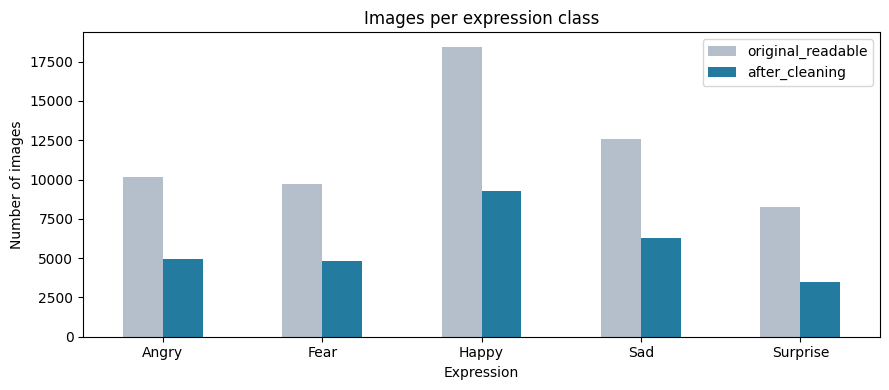

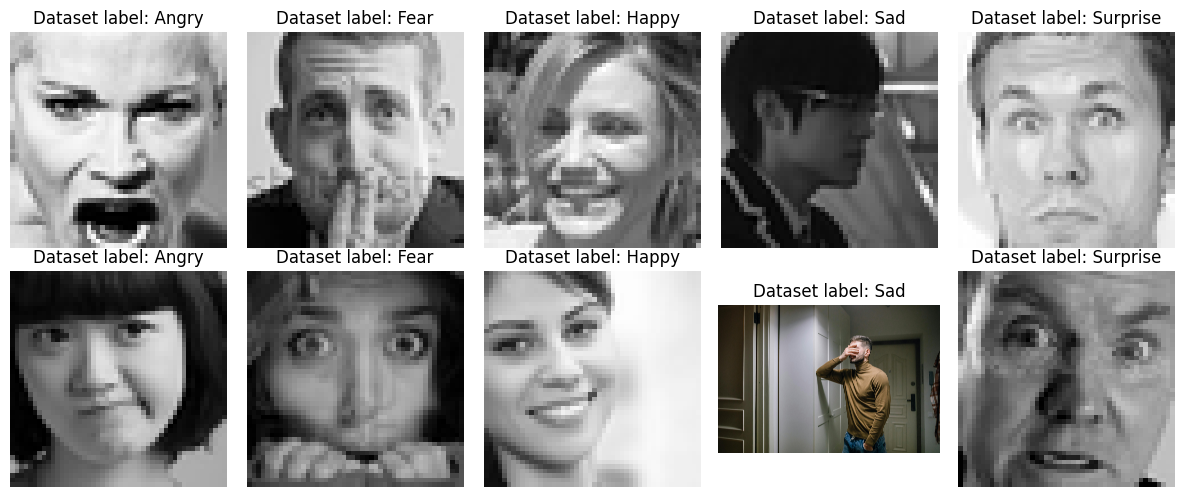

,image_size,width,height,image_count
0,48 x 48,48,48,57756
1,640 x 640,640,640,864
2,4000 x 6000,4000,6000,23
3,150 x 100,150,100,16
4,6000 x 4000,6000,4000,16
5,1600 x 1067,1600,1067,12
6,150 x 225,150,225,7
7,4480 x 6720,4480,6720,7
8,6720 x 4480,6720,4480,7
9,2000 x 3000,2000,3000,6


In [5]:
counts.plot(kind='bar', figsize=(9, 4), color=['#b5becb', '#247ba0'])
plt.title('Images per expression class')
plt.xlabel('Expression')
plt.ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
if RESUME_CHECKPOINT is None:
    plt.savefig(RUN_DIR / 'class_distribution.png', dpi=150)
plt.show()

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(12, 5))
for column, label in enumerate(CLASS_NAMES):
    examples = clean[clean.label == label].sample(2, random_state=SEED)
    for row, (_, item) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / item.path) as image:
            axes[row, column].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, column].set_title(f'Dataset label: {label}')
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()
image_sizes = (
    manifest.groupby(['width', 'height'])
    .size()
    .reset_index(name='image_count')
    .sort_values('image_count', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

image_sizes.insert(0, 'image_size', image_sizes['width'].astype(str) + ' x ' + image_sizes['height'].astype(str))
display(image_sizes)


### Dataset Splitting (70:15:15)

Dataset yang telah melalui proses cleaning dibagi menjadi tiga subset menggunakan `train_test_split()` dari Scikit-learn.

- **Training (70%)**: Digunakan untuk melatih CNN dan memperbarui bobot model melalui backpropagation.
- **Validation (15%)**: Digunakan untuk memantau performa model selama training serta memilih model terbaik.
- **Testing (15%)**: Digunakan untuk mengevaluasi performa akhir model terhadap data yang belum digunakan dalam training maupun pemilihan model.

Pembagian dilakukan dua tahap, yaitu memisahkan 70% training dan 30% data sementara, kemudian membagi data sementara menjadi dua bagian sama besar.

Parameter `stratify` mempertahankan proporsi setiap kelas ekspresi, sedangkan `random_state=SEED` memastikan pembagian data dapat direproduksi.

Selain itu, dilakukan pemeriksaan keunikan path dan hash piksel untuk memastikan tidak terdapat duplikat identik pada dataset hasil pembagian.

In [6]:
train_df, remaining_df = train_test_split(
    clean,
    test_size=0.30,
    stratify=clean.target,
    random_state=SEED
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df.target,
    random_state=SEED
)

train_df, val_df, test_df = (
    frame.reset_index(drop=True)
    for frame in (train_df, val_df, test_df)
)

split_manifest = pd.concat([
    train_df.assign(split='train'),
    val_df.assign(split='validation'),
    test_df.assign(split='test')
], ignore_index=True)

assert split_manifest.path.is_unique
assert split_manifest.pixel_sha256.is_unique
assert len(split_manifest) == len(clean)
assert set(train_df.target) == set(val_df.target) == set(test_df.target) == set(range(len(CLASS_NAMES)))


display(
    pd.crosstab(
        split_manifest.label,
        split_manifest.split
    ).reindex(CLASS_NAMES)[['train', 'validation', 'test']]
)

print('No exact decoded-pixel duplicates cross the splits.')

# Fingerprint exact membership and labels before resuming training.
split_rows = split_manifest[['split', 'path', 'target', 'pixel_sha256']].sort_values(['split', 'path'])
config['split_sha256'] = hashlib.sha256(split_rows.to_csv(index=False).encode('utf-8')).hexdigest()
assert config['split_sha256'] == BASELINE_SPLIT_SHA256, (
    'Dataset/split differs from CNN_improved.ipynb; comparison is invalid.'
)
config_path = RUN_DIR / 'config.json'
if RESUME_CHECKPOINT is None:
    config_path.write_text(json.dumps(config, indent=2))
    (RUN_DIR / 'environment_versions.json').write_text(json.dumps(versions, indent=2))
else:
    assert config_path.is_file(), 'Missing config.json in resume directory.'
    saved_config = json.loads(config_path.read_text())
    if saved_config != config:
        raise ValueError('Resume rejected: training configuration or split differs from this run.')
split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
print('Split SHA-256:', config['split_sha256'])


split,train,validation,test
label,,,
Angry,3471,744,744
Fear,3375,723,724
Happy,6478,1389,1388
Sad,4417,946,947
Surprise,2431,521,520


No exact decoded-pixel duplicates cross the splits.
Split SHA-256: 1ef54c784c90e488f83b1db34cf96358f0376a17f648cfdf6feb31e4125b0f1b


## 7. Tensor, augmentation, dan DataLoader
Eval memakai grayscale 64 × 64, `ToTensor`, dan normalisasi yang sama dengan notebook asli.
Train juga memakai horizontal flip serta rotasi maksimum 7° dan translasi maksimum 4%
agar variasi pose bertambah tanpa mengubah ekspresi utama. Transformasi acak hanya diterapkan
pada train. Batch size 64 dan `NUM_WORKERS=0` tetap aman untuk Colab GPU T4.


In [7]:
train_steps = [
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
]
if USE_AUGMENTATION:
    train_steps.extend([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomAffine(
            degrees=AUGMENT_DEGREES,
            translate=(AUGMENT_TRANSLATE, AUGMENT_TRANSLATE),
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=128,
        ),
    ])
train_steps.extend([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_transform = transforms.Compose(train_steps)
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

class FaceDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.frame = frame.reset_index(drop=True)
        self.root, self.transform = Path(root), transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        item = self.frame.iloc[index]
        with Image.open(self.root / item.path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            tensor = self.transform(image)
        return tensor, int(item.target)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)

def make_loaders():
    generator = torch.Generator().manual_seed(SEED)
    options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
                   worker_init_fn=seed_worker)
    train_loader = DataLoader(FaceDataset(train_df, DATA_DIR, train_transform), shuffle=True, generator=generator, **options)
    val_loader = DataLoader(FaceDataset(val_df, DATA_DIR, eval_transform), shuffle=False, **options)
    test_loader = DataLoader(FaceDataset(test_df, DATA_DIR, eval_transform), shuffle=False, **options)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
images, labels = next(iter(train_loader))

print('Image batch:', tuple(images.shape), '= (batch, channel, height, width)')
print('Label batch:', tuple(labels.shape))
print('Pixel range:', images.min().item(), images.max().item())


Image batch: (64, 1, 64, 64) = (batch, channel, height, width)
Label batch: (64,)
Pixel range: -1.0 1.0


## 8. Bangun CNN dari awal
**Conv2d:** mempelajari pola lokal pada gambar. **ReLU:** memberi kemampuan mempelajari hubungan nonlinier.
**MaxPool2d:** mengecilkan ukuran fitur. **Linear:** mengubah fitur menjadi lima skor kelas.
**Dropout:** menonaktifkan sebagian fitur secara acak saat latihan untuk membantu mengurangi overfitting.

Alur bentuk tensor: `1×64×64 → 32×32×32 → 64×16×16 → 128×8×8 → 128×4×4 → 5 skor`.
Keluaran berupa **logits** (skor mentah). Jangan menambahkan softmax sebelum `CrossEntropyLoss`;
softmax baru dipakai ketika menampilkan skor prediksi.

In [8]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN(len(CLASS_NAMES)).to(DEVICE)
with torch.no_grad():
    sample_logits = model(images[:2].to(DEVICE))
assert sample_logits.shape == (2, len(CLASS_NAMES))
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Output for 2 images:', tuple(sample_logits.shape))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)
Trainable parameters: 355589
Output for 2 images: (2, 5)


## 9. Loss, optimizer, dan metrik satu epoch
Bobot kelas dihitung hanya dari train, seperti notebook asli. Bobot Fear kemudian dikalikan 1,25 sesuai indeks label. `CrossEntropyLoss` dan
arsitektur `SimpleCNN` dipertahankan agar perubahan strategi training dapat dibandingkan.
Eksperimen ini memakai AdamW dengan weight decay `1e-4`. Macro F1 adalah metrik
utama pemilihan checkpoint; accuracy dan loss tetap dicatat untuk diagnosis.


In [9]:
train_counts = np.bincount(train_df.target.to_numpy(), minlength=len(CLASS_NAMES))
weights = len(train_df) / (len(CLASS_NAMES) * train_counts)
assert USE_CLASS_WEIGHTS, 'Fear-weight experiment requires class-weighted loss.'
assert all(CLASS_TO_INDEX[name] == index for index, name in enumerate(CLASS_NAMES))
fear_index = CLASS_TO_INDEX['Fear']
assert CLASS_NAMES[fear_index] == 'Fear'
assert len(weights) == len(CLASS_NAMES)
baseline_weights = weights.copy()
weights[fear_index] *= FEAR_WEIGHT_MULTIPLIER
assert np.allclose(np.delete(weights, fear_index), np.delete(baseline_weights, fear_index))
assert np.isclose(weights[fear_index], baseline_weights[fear_index] * 1.25)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
display(pd.DataFrame({'class': CLASS_NAMES, 'train_count': train_counts,
                      'baseline_loss_weight': baseline_weights, 'loss_weight': weights}))

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, loss_denominator = 0.0, 0.0
    all_targets, all_predictions = [], []
    for images, targets in tqdm(loader, desc='Train' if training else 'Evaluate', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
        # CrossEntropyLoss(weight=...) divides by the sum of the observed class weights.
        denominator = criterion.weight[targets].sum().item() if criterion.weight is not None else targets.numel()
        loss_sum += loss.item() * denominator
        loss_denominator += denominator
        all_targets.extend(targets.detach().cpu().tolist())
        all_predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
    metrics = {
        'loss': loss_sum / loss_denominator,
        'accuracy': accuracy_score(all_targets, all_predictions),
        'macro_f1': f1_score(all_targets, all_predictions, labels=list(range(len(CLASS_NAMES))),
                             average='macro', zero_division=0),
    }
    return metrics, np.asarray(all_targets), np.asarray(all_predictions)

,class,train_count,baseline_loss_weight,loss_weight
0,Angry,3471,1.162316,1.162316
1,Fear,3375,1.195378,1.494222
2,Happy,6478,0.622785,0.622785
3,Sad,4417,0.913380,0.913380
4,Surprise,2431,1.659564,1.659564


## 10. Training, scheduler, dan checkpoint
Run baru selalu memakai folder unik dan mulai dari awal. Resume hanya terjadi jika
`RESUME_CHECKPOINT` diisi secara eksplisit; konfigurasi, split, optimizer, scheduler,
dan keadaan generator dipulihkan dari checkpoint yang cocok. Scheduler menurunkan LR
saat validation macro F1 mendatar. Checkpoint terbaik dipilih dari validation macro F1,
dan early stopping berhenti setelah 10 epoch tanpa peningkatan bermakna.

Test set tidak digunakan selama pemilihan model atau hyperparameter.


In [10]:
import os

resume_path = RUN_DIR / 'last_checkpoint.pt'
checkpoint_path = RUN_DIR / 'best_model.pt'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

train_loader, val_loader, test_loader = make_loaders()
model = SimpleCNN(len(CLASS_NAMES)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=SCHEDULER_FACTOR, patience=SCHEDULER_PATIENCE,
    threshold=MIN_DELTA, threshold_mode='abs', min_lr=MIN_LR,
)

start_epoch = 1
best_val_f1 = -1.0
best_epoch = 0
stale_epochs = 0
history = []

if RESUME_CHECKPOINT is not None:
    checkpoint = torch.load(resume_path, map_location=DEVICE, weights_only=True)
    if checkpoint.get('config') != config:
        raise ValueError('Resume rejected: checkpoint configuration or split differs.')
    if checkpoint_path.exists():
        best_saved = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
        if (best_saved.get('config') != config
                or best_saved.get('best_epoch') != checkpoint['best_epoch']
                or abs(best_saved.get('validation_macro_f1', -1) - checkpoint['best_val_f1']) > 1e-12):
            raise ValueError('Resume rejected: best checkpoint does not match last checkpoint.')
    elif checkpoint['best_epoch'] > 0:
        raise FileNotFoundError('Best checkpoint missing from resume directory.')

    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_f1 = checkpoint['best_val_f1']
    best_epoch = checkpoint['best_epoch']
    stale_epochs = checkpoint['stale_epochs']
    history = checkpoint['history']
    random.setstate(checkpoint['python_rng_state'])
    np_state = checkpoint['numpy_rng_state']
    np.random.set_state((np_state[0], np.array(np_state[1], dtype=np.uint32),
                         np_state[2], np_state[3], np_state[4]))
    torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
    if DEVICE.type == 'cuda' and 'cuda_rng_state' in checkpoint:
        torch.cuda.set_rng_state_all([state.cpu() for state in checkpoint['cuda_rng_state']])
    train_loader.generator.set_state(checkpoint['loader_rng_state'].cpu())
    print(f'Resuming from epoch {start_epoch}')
else:
    assert not resume_path.exists() and not checkpoint_path.exists(), 'Fresh run directory is not empty.'
    print('Starting a fresh run at epoch 1')

if stale_epochs >= PATIENCE:
    print('Run already met early stopping; no additional epochs will run.')
elif start_epoch > EPOCHS:
    print('Run already reached the maximum epoch count.')
else:
    for epoch in range(start_epoch, EPOCHS + 1):
        started = time.perf_counter()
        learning_rate_used = optimizer.param_groups[0]['lr']
        train_metrics, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        val_metrics, _, _ = run_epoch(model, val_loader, criterion)
        scheduler.step(val_metrics['macro_f1'])

        history.append({
            'epoch': epoch,
            'learning_rate': learning_rate_used,
            **{f'train_{key}': value for key, value in train_metrics.items()},
            **{f'val_{key}': value for key, value in val_metrics.items()},
            'seconds': time.perf_counter() - started,
        })
        print(
            f"Epoch {epoch}/{EPOCHS} | LR {learning_rate_used:.2e} | "
            f"train loss {train_metrics['loss']:.4f} | val loss {val_metrics['loss']:.4f} | "
            f"val accuracy {val_metrics['accuracy']:.4f} | "
            f"val macro-F1 {val_metrics['macro_f1']:.4f}"
        )

        if val_metrics['macro_f1'] > best_val_f1 + MIN_DELTA:
            best_val_f1 = val_metrics['macro_f1']
            best_epoch = epoch
            stale_epochs = 0
            best_payload = {
                'model_state_dict': {key: value.detach().cpu() for key, value in model.state_dict().items()},
                'class_names': CLASS_NAMES,
                'image_size': IMAGE_SIZE,
                'best_epoch': best_epoch,
                'validation_macro_f1': float(best_val_f1),
                'config': config,
            }
            best_temp = RUN_DIR / 'best_model.tmp'
            torch.save(best_payload, best_temp)
            os.replace(best_temp, checkpoint_path)
            print('Saved new best validation checkpoint.')
        else:
            stale_epochs += 1

        np_state = np.random.get_state()
        latest_checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'best_val_f1': best_val_f1,
            'best_epoch': best_epoch,
            'stale_epochs': stale_epochs,
            'history': history,
            'config': config,
            'python_rng_state': random.getstate(),
            'numpy_rng_state': (np_state[0], np_state[1].tolist(), np_state[2], np_state[3], np_state[4]),
            'torch_rng_state': torch.get_rng_state(),
            'loader_rng_state': train_loader.generator.get_state(),
        }
        if DEVICE.type == 'cuda':
            latest_checkpoint['cuda_rng_state'] = torch.cuda.get_rng_state_all()
        latest_temp = RUN_DIR / 'last_checkpoint.tmp'
        torch.save(latest_checkpoint, latest_temp)
        os.replace(latest_temp, resume_path)
        pd.DataFrame(history).to_csv(RUN_DIR / 'history.csv', index=False)

        if stale_epochs >= PATIENCE:
            print(f'Early stopping: no validation macro-F1 gain > {MIN_DELTA} for {PATIENCE} epochs.')
            break

print(f'Best epoch: {best_epoch}; validation macro-F1: {best_val_f1:.4f}')


Starting a fresh run at epoch 1


Train:   0%|          | 0/316 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 1/50 | LR 1.00e-03 | train loss 1.5370 | val loss 1.4489 | val accuracy 0.3949 | val macro-F1 0.3575
Saved new best validation checkpoint.


Train:   0%|          | 0/316 [00:00<?, ?it/s]

...

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 49/50 | LR 6.25e-05 | train loss 0.8051 | val loss 0.9508 | val accuracy 0.6364 | val macro-F1 0.6132


Train:   0%|          | 0/316 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Epoch 50/50 | LR 6.25e-05 | train loss 0.8102 | val loss 0.9501 | val accuracy 0.6361 | val macro-F1 0.6136
Best epoch: 47; validation macro-F1: 0.6175


In [11]:
print('Checkpoint found:', resume_path.exists())
if resume_path.exists():
    saved = torch.load(resume_path, map_location='cpu', weights_only=True)
    print('Last epoch:', saved['epoch'])
    print('Best epoch:', saved['best_epoch'])
    print('Best validation macro-F1:', saved['best_val_f1'])
    print('Stale epochs:', saved['stale_epochs'])
    print('Next learning rate:', optimizer.param_groups[0]['lr'])


Checkpoint found: True
Last epoch: 50
Best epoch: 47
Best validation macro-F1: 0.6174599263337421
Stale epochs: 3
Next learning rate: 6.25e-05


In [12]:
best_checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
if best_checkpoint.get('config') != config:
    raise ValueError('Best checkpoint configuration does not match this run.')
model.load_state_dict(best_checkpoint['model_state_dict'])
model.eval()
val_metrics_best, val_true, val_pred = run_epoch(model, val_loader, criterion)
print(f"Best epoch: {best_checkpoint['best_epoch']}")
print(f"Validation accuracy: {val_metrics_best['accuracy'] * 100:.2f}%")
print(f"Validation macro F1: {val_metrics_best['macro_f1'] * 100:.2f}%")
print(f"Validation loss: {val_metrics_best['loss']:.4f}")


Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Best epoch: 47
Validation accuracy: 63.94%
Validation macro F1: 61.75%
Validation loss: 0.9527


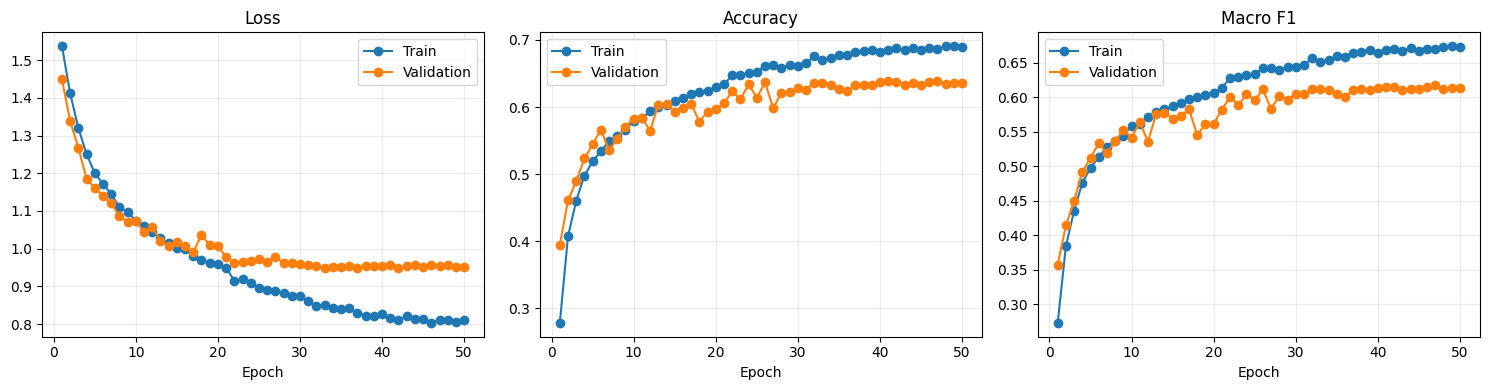

,epoch,learning_rate,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,seconds
0,1,0.001000,1.537044,0.278108,0.272894,1.448920,0.394865,0.357484,127.513451
1,2,0.001000,1.412123,0.407545,0.384384,1.337734,0.461022,0.414096,119.583414
2,3,0.001000,1.319539,0.460440,0.435638,1.267406,0.489244,0.449926,121.611831
3,4,0.001000,1.251048,0.497769,0.475957,1.185357,0.523479,0.491486,119.417984
4,5,0.001000,1.199709,0.518937,0.497004,1.160573,0.544298,0.512160,119.061713
5,6,0.001000,1.171961,0.534057,0.513298,1.140075,0.566273,0.532819,120.617495
6,7,0.001000,1.144213,0.549326,0.527708,1.120260,0.535970,0.518912,119.904880
7,8,0.001000,1.111346,0.557307,0.537053,1.085958,0.551932,0.536082,120.679317
8,9,0.001000,1.096746,0.566082,0.544310,1.070595,0.570669,0.552152,119.209415
9,10,0.001000,1.074369,0.579665,0.558773,1.072573,0.582697,0.541465,118.992467


In [13]:
history_df = pd.read_csv(RUN_DIR / 'history.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, metric in zip(axes, ['loss', 'accuracy', 'macro_f1']):
    axis.plot(history_df.epoch, history_df[f'train_{metric}'], marker='o', label='Train')
    axis.plot(history_df.epoch, history_df[f'val_{metric}'], marker='o', label='Validation')
    axis.set(title=metric.replace('_', ' ').title(), xlabel='Epoch')
    axis.legend()
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RUN_DIR / 'training_curves.png', dpi=150)
plt.show()
display(history_df)

{
  "loss": 0.9527032518910397,
  "accuracy": 0.6393708073097386,
  "macro_f1": 0.6174599263337421,
  "best_epoch": 47,
  "validation_samples": 4323
}


,precision,recall,f1-score,support
Angry,0.540962,0.559140,0.549901,744.000000
Fear,0.428230,0.495159,0.459269,723.000000
Happy,0.864511,0.808495,0.835565,1389.000000
Sad,0.569378,0.503171,0.534231,946.000000
Surprise,0.670669,0.750480,0.708333,521.000000
accuracy,0.639371,0.639371,0.639371,0.639371
macro avg,0.614750,0.623289,0.617460,4323.000000
weighted avg,0.647916,0.639371,0.642193,4323.000000


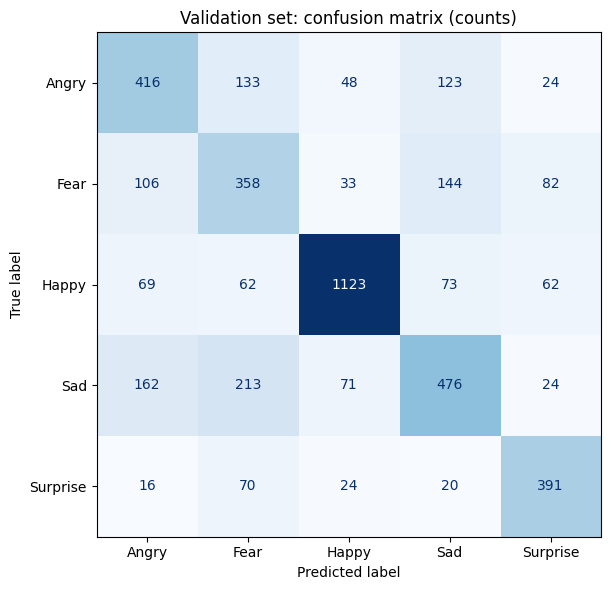

In [14]:
class_ids = list(range(len(CLASS_NAMES)))
report = classification_report(val_true, val_pred, labels=class_ids, target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(RUN_DIR / 'validation_classification_report.csv')
validation_results = {**val_metrics_best, 'best_epoch': best_checkpoint['best_epoch'],
                      'validation_samples': len(val_df)}
(RUN_DIR / 'validation_metrics.json').write_text(json.dumps(validation_results, indent=2))
print(json.dumps(validation_results, indent=2))
display(report_df)

predictions = val_df[['path', 'label', 'target']].copy()
predictions['predicted_index'] = val_pred
predictions['predicted_label'] = [CLASS_NAMES[index] for index in val_pred]
predictions.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)
cm = confusion_matrix(val_true, val_pred, labels=class_ids)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / 'validation_confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Validation set: confusion matrix (counts)')
plt.tight_layout()
plt.savefig(RUN_DIR / 'validation_confusion_matrix.png', dpi=150)
plt.show()


### Perbandingan validation dengan `CNN_improved.ipynb`

Acuan berikut berasal dari output validation yang tersimpan pada notebook baseline (best epoch 38, 4.323 sampel). Angka Fear pada classification report baseline ditampilkan sampai enam desimal. Perbandingan memakai validation saja; selisih dinyatakan dalam percentage points. Loss antar eksperimen tidak dibandingkan karena bobot loss berubah.


In [15]:
assert config['split_sha256'] == BASELINE_SPLIT_SHA256
assert len(val_df) == 4323 and int(report['Fear']['support']) == 723, (
    'Validation population differs from CNN_improved.ipynb.'
)
baseline_validation = {
    'Fear precision': 0.454400,
    'Fear recall': 0.392808,
    'Fear F1': 0.421365,
    'Overall macro F1': 0.6139146030830311,
}
current_validation = {
    'Fear precision': report['Fear']['precision'],
    'Fear recall': report['Fear']['recall'],
    'Fear F1': report['Fear']['f1-score'],
    'Overall macro F1': val_metrics_best['macro_f1'],
}
comparison_df = pd.DataFrame({
    'CNN_improved': baseline_validation,
    'CNN_fear_weight': current_validation,
})
comparison_df['delta_percentage_points'] = (
    comparison_df['CNN_fear_weight'] - comparison_df['CNN_improved']
) * 100
comparison_df.to_csv(RUN_DIR / 'validation_vs_improved_baseline.csv')
display(comparison_df)


,CNN_improved,CNN_fear_weight,delta_percentage_points
Fear precision,0.454400,0.428230,-2.617033
Fear recall,0.392808,0.495159,10.235106
Fear F1,0.421365,0.459269,3.790376
Overall macro F1,0.613915,0.617460,0.354532


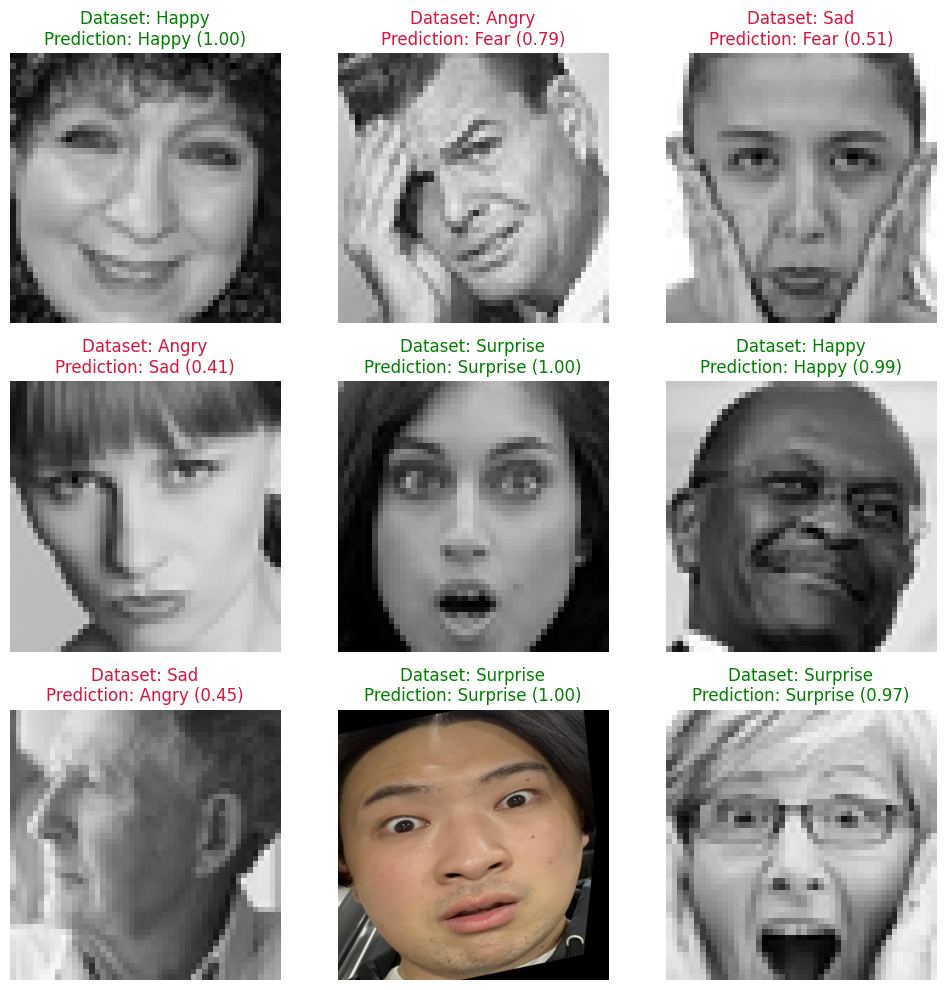

In [16]:
@torch.inference_mode()
def predict_image(path):
    model.eval()
    with Image.open(path) as image:
        rgb = ImageOps.exif_transpose(image).convert('RGB')
        tensor = eval_transform(rgb).unsqueeze(0).to(DEVICE)
    scores = torch.softmax(model(tensor), dim=1).squeeze(0).cpu().numpy()
    return CLASS_NAMES[int(scores.argmax())], {name: float(score) for name, score in zip(CLASS_NAMES, scores)}

examples = val_df.sample(n=min(9, len(val_df)), random_state=SEED)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for axis in axes.flat:
    axis.axis('off')
for axis, (_, item) in zip(axes.flat, examples.iterrows()):
    path = DATA_DIR / item.path
    predicted_label, scores = predict_image(path)
    with Image.open(path) as image:
        axis.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    axis.set_title(f'Dataset: {item.label}\nPrediction: {predicted_label} ({scores[predicted_label]:.2f})',
                   color='green' if predicted_label == item.label else 'crimson')
plt.tight_layout()
plt.savefig(RUN_DIR / 'validation_sample_predictions.png', dpi=150)
plt.show()


In [17]:
experiment_log = pd.DataFrame([{
    'run': RUN_DIR.name,
    'experiment': EXPERIMENT_NAME,
    'seed': SEED,
    'split_sha256': config['split_sha256'],
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'optimizer': 'AdamW',
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'epochs_completed': len(history),
    'best_epoch': best_checkpoint['best_epoch'],
    'augmentation': USE_AUGMENTATION,
    'class_weights': USE_CLASS_WEIGHTS,
    'fear_weight_multiplier': FEAR_WEIGHT_MULTIPLIER,
    'validation_accuracy': val_metrics_best['accuracy'],
    'validation_macro_f1': val_metrics_best['macro_f1'],
    'validation_fear_f1': report['Fear']['f1-score'],
}])
experiment_log.to_csv(RUN_DIR / 'experiment_log.csv', index=False)
display(experiment_log)
print('Persistent Google Drive folder:', RUN_DIR)


,run,experiment,seed,split_sha256,image_size,batch_size,optimizer,learning_rate,weight_decay,epochs_completed,best_epoch,augmentation,class_weights,fear_weight_multiplier,validation_accuracy,validation_macro_f1,validation_fear_f1
0,20261019T080704Z_aa77fb25,simplecnn_mild_aug_adamw_fear125_v1,42,1ef54c784c90e488f83b1db34cf96358f0376a17f648cf...,64,64,AdamW,0.001,0.0001,50,47,True,True,1.25,0.639371,0.61746,0.459269


Persistent Google Drive folder: /content/drive/MyDrive/fer_cnn_outputs/simplecnn_mild_aug_adamw_fear125_v1/20261019T080704Z_aa77fb25


## Evaluasi final pada test set (opsional)
Pilih konfigurasi dan checkpoint menggunakan validation saja. Setelah semua keputusan
hyperparameter final, ubah `RUN_FINAL_TEST` menjadi `True` dan jalankan sel berikut satu kali.
Test tidak dipakai oleh scheduler, early stopping, atau pemilihan model.

In [18]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    final_checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    if final_checkpoint.get('config') != config:
        raise ValueError('Final checkpoint does not match this run.')
    model.load_state_dict(final_checkpoint['model_state_dict'])
    test_metrics, test_true, test_pred = run_epoch(model, test_loader, criterion)
    test_report = classification_report(
        test_true, test_pred, labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0,
    )
    test_results = {**test_metrics, 'best_epoch': final_checkpoint['best_epoch'],
                    'test_samples': len(test_df)}
    (RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_results, indent=2))
    pd.DataFrame(test_report).transpose().to_csv(RUN_DIR / 'test_classification_report.csv')
    test_cm = confusion_matrix(test_true, test_pred, labels=list(range(len(CLASS_NAMES))))
    pd.DataFrame(test_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        RUN_DIR / 'test_confusion_matrix.csv'
    )
    print(json.dumps(test_results, indent=2))
    display(pd.DataFrame(test_report).transpose())
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(test_cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title('Final test set: confusion matrix (counts)')
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'test_confusion_matrix.png', dpi=150)
    plt.show()
else:
    print('Test set remains untouched. Use validation to choose hyperparameters.')

Test set remains untouched. Use validation to choose hyperparameters.


In [19]:
DOWNLOAD_RESULTS = True  # Change to True if you want a download.
if DOWNLOAD_RESULTS:
    from google.colab import files
    results_zip = shutil.make_archive(f'/content/{RUN_DIR.name}_results', 'zip', root_dir=RUN_DIR)
    files.download(results_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>